# Tutorial práctico: PCA aplicado a series de tiempo

Este notebook está alineado con las ideas de las slides de PCA en series de tiempo (S07-PCAST):

1. Reducción de dimensión con PCA.
2. Selección de técnica y parámetros.
3. Validación temporal rigurosa.
4. Interpretación de componentes y diagnóstico.

Usaremos una serie real (`airline_passengers.csv`) y construiremos un enfoque de **lag-embedding** para convertirla en un problema supervisado.

## 1) Setup

Compararemos dos técnicas basadas en PCA para pronóstico un paso adelante:

- `PCA + LinearRegression`
- `PCA + Ridge`

Además, contrastaremos contra un baseline estacional naive.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)

## 2) Cargar serie y exploración inicial

,pasajeros
fecha,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


Observaciones: 144


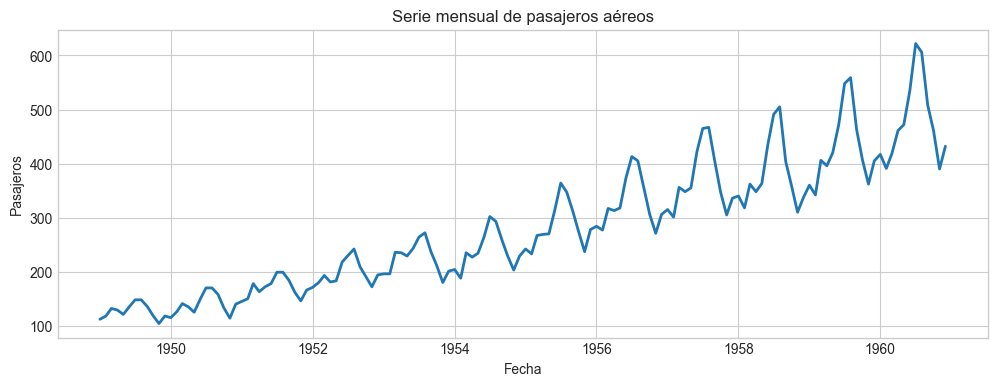

In [2]:
df = pd.read_csv('airline_passengers.csv', parse_dates=['Month'])
df = df.rename(columns={'Month': 'fecha', 'Passengers': 'pasajeros'})
df = df.set_index('fecha').asfreq('MS')

serie = df['pasajeros']

display(df.head())
print(f'Observaciones: {len(serie)}')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(serie, lw=2, color='tab:blue')
ax.set_title('Serie mensual de pasajeros aéreos')
ax.set_xlabel('Fecha')
ax.set_ylabel('Pasajeros')
plt.show()

## 3) Partición temporal: train / valid / test

La selección de parámetros se realiza en validación y la calidad final se reporta en test.

Train: 1949-01-01 -> 1956-12-01 | n=96
Valid: 1957-01-01 -> 1958-12-01 | n=24
Test : 1959-01-01 -> 1960-12-01 | n=24


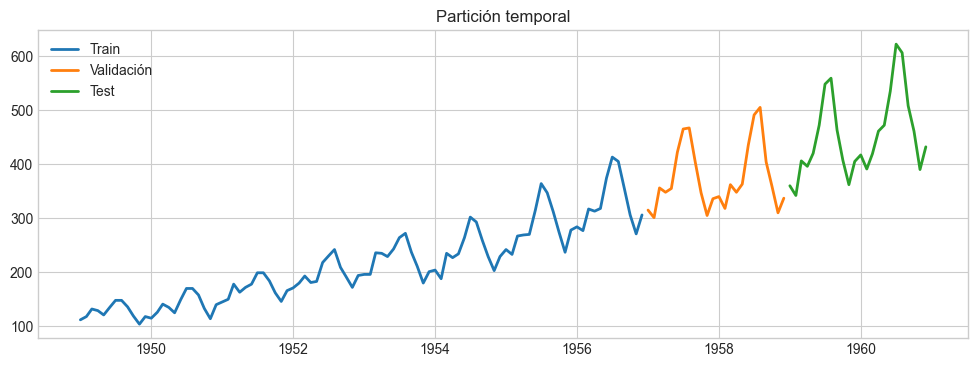

In [3]:
n_total = len(serie)
n_test = 24
n_valid = 24

train = serie.iloc[: n_total - n_valid - n_test]
valid = serie.iloc[n_total - n_valid - n_test : n_total - n_test]
test = serie.iloc[n_total - n_test :]

print(f'Train: {train.index.min().date()} -> {train.index.max().date()} | n={len(train)}')
print(f'Valid: {valid.index.min().date()} -> {valid.index.max().date()} | n={len(valid)}')
print(f'Test : {test.index.min().date()} -> {test.index.max().date()} | n={len(test)}')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train, label='Train', lw=2)
ax.plot(valid, label='Validación', lw=2)
ax.plot(test, label='Test', lw=2)
ax.set_title('Partición temporal')
ax.legend()
plt.show()

## 4) Funciones auxiliares

Implementamos métricas, lag-embedding y pipeline de modelado.

In [4]:
def mae(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))


def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))


def mape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


def eval_metrics(y_true, y_pred):
    return {
        'MAE': mae(y_true, y_pred),
        'RMSE': rmse(y_true, y_pred),
        'MAPE_%': mape(y_true, y_pred),
    }


def make_supervised(series_values, window):
    arr = np.asarray(series_values, dtype=float)
    X, y = [], []
    for t in range(window, len(arr)):
        X.append(arr[t - window : t])
        y.append(arr[t])
    return np.array(X), np.array(y)


def build_pipeline(config):
    steps = []
    if config['scale']:
        steps.append(('scaler', StandardScaler()))

    steps.append(('pca', PCA(n_components=config['n_components'])))

    if config['technique'] == 'PCA+Linear':
        steps.append(('model', LinearRegression()))
    else:
        steps.append(('model', Ridge(alpha=config['alpha'])))

    return Pipeline(steps)


def walk_forward_forecast(initial_series, eval_series, config):
    history = list(np.asarray(initial_series, dtype=float))
    preds = []

    for y_real in np.asarray(eval_series, dtype=float):
        X_train, y_train = make_supervised(history, config['window'])
        if len(X_train) < 20:
            raise ValueError('Muy pocos datos para entrenar en esta configuración.')

        model = build_pipeline(config)
        model.fit(X_train, y_train)

        x_next = np.array(history[-config['window'] :]).reshape(1, -1)
        y_pred = float(model.predict(x_next)[0])
        preds.append(y_pred)

        # Walk-forward con actualización usando el valor observado.
        history.append(y_real)

    return np.array(preds)

## 5) Selección de técnica y parámetros

Buscamos la mejor configuración sobre la ventana de validación. Parámetros:

- Técnica: `PCA+Linear` o `PCA+Ridge`
- Ventana de embedding (`window`)
- Estandarización (`scale`)
- Número de componentes (`n_components`)
- Penalización `alpha` (solo Ridge)

In [5]:
windows = [12, 18, 24]
scales = [False, True]
components = [2, 3, 4, 6, 8]
techniques = ['PCA+Linear', 'PCA+Ridge']
alphas = [0.1, 1.0, 10.0]

configs = []
for technique, window, scale, n_components in product(techniques, windows, scales, components):
    if n_components >= window:
        continue

    if technique == 'PCA+Linear':
        configs.append({
            'technique': technique,
            'window': window,
            'scale': scale,
            'n_components': n_components,
            'alpha': np.nan,
        })
    else:
        for alpha in alphas:
            configs.append({
                'technique': technique,
                'window': window,
                'scale': scale,
                'n_components': n_components,
                'alpha': alpha,
            })

results = []
for cfg in configs:
    try:
        pred_valid = walk_forward_forecast(train.values, valid.values, cfg)
        metrics = eval_metrics(valid.values, pred_valid)
        results.append({**cfg, **metrics})
    except Exception:
        continue

results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
print(f'Configuraciones evaluadas: {len(results_df)}')
display(results_df.head(12))

Configuraciones evaluadas: 120


,technique,window,scale,n_components,alpha,MAE,RMSE,MAPE_%
0,PCA+Ridge,12,True,8,1.0,17.656787,21.856006,4.910593
1,PCA+Ridge,12,True,8,0.1,17.894712,21.985414,4.942504
2,PCA+Linear,12,True,8,NaN,17.930455,22.019210,4.947930
3,PCA+Ridge,12,True,6,1.0,17.354754,22.563080,4.838495
4,PCA+Ridge,12,True,6,0.1,17.226994,22.656997,4.792739
5,PCA+Linear,12,True,6,NaN,17.213886,22.677195,4.787638
6,PCA+Ridge,18,True,8,0.1,18.767895,23.008808,5.133399
7,PCA+Linear,18,True,8,NaN,18.767194,23.019100,5.128166
8,PCA+Ridge,18,True,8,1.0,18.939074,23.035753,5.209011
9,PCA+Ridge,12,False,8,10.0,18.863413,23.208086,5.221004


Mejor configuración en validación (por RMSE):
{'technique': 'PCA+Ridge', 'window': 12, 'scale': True, 'n_components': 8, 'alpha': 1.0, 'MAE': 17.656787123800488, 'RMSE': 21.856006283977152, 'MAPE_%': 4.910592664954721}


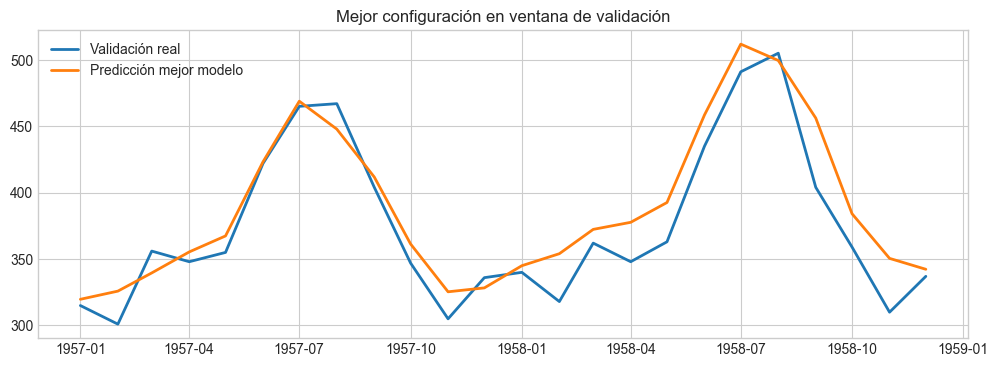

Métricas del mejor modelo en validación:
{'MAE': np.float64(17.656787123800488), 'RMSE': np.float64(21.856006283977152), 'MAPE_%': np.float64(4.910592664954721)}


In [6]:
best_cfg = results_df.iloc[0].to_dict()
print('Mejor configuración en validación (por RMSE):')
print(best_cfg)

pred_valid_best = walk_forward_forecast(train.values, valid.values, best_cfg)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(valid.index, valid.values, label='Validación real', lw=2)
ax.plot(valid.index, pred_valid_best, label='Predicción mejor modelo', lw=2)
ax.set_title('Mejor configuración en ventana de validación')
ax.legend()
plt.show()

print('Métricas del mejor modelo en validación:')
print(eval_metrics(valid.values, pred_valid_best))

## 6) Evaluación final en test y comparación con baseline

Reentrenamos en `train+valid` usando la mejor configuración y evaluamos en `test`.

,modelo,MAE,RMSE,MAPE_%
0,PCA (mejor configuración),16.258172,19.641318,3.698475
1,Baseline estacional naive,47.583333,49.986665,10.522728


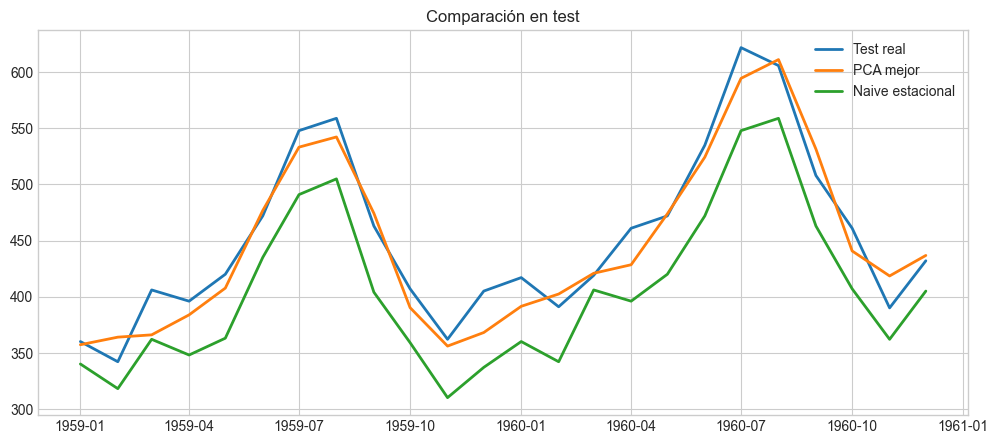

In [7]:
def seasonal_naive_walk_forward(initial_series, eval_series, season=12):
    history = list(np.asarray(initial_series, dtype=float))
    preds = []
    for y_real in np.asarray(eval_series, dtype=float):
        y_pred = history[-season]
        preds.append(y_pred)
        history.append(y_real)
    return np.array(preds)

train_valid = pd.concat([train, valid])

pred_test_best = walk_forward_forecast(train_valid.values, test.values, best_cfg)
pred_test_naive = seasonal_naive_walk_forward(train_valid.values, test.values, season=12)

metrics_best = eval_metrics(test.values, pred_test_best)
metrics_naive = eval_metrics(test.values, pred_test_naive)

comparison = pd.DataFrame([
    {'modelo': 'PCA (mejor configuración)', **metrics_best},
    {'modelo': 'Baseline estacional naive', **metrics_naive},
]).sort_values('RMSE')

display(comparison)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test.index, test.values, label='Test real', lw=2)
ax.plot(test.index, pred_test_best, label='PCA mejor', lw=2)
ax.plot(test.index, pred_test_naive, label='Naive estacional', lw=2)
ax.set_title('Comparación en test')
ax.legend()
plt.show()

## 7) Interpretación del PCA elegido

Ajustamos el pipeline sobre `train+valid` para inspeccionar varianza explicada y loadings.

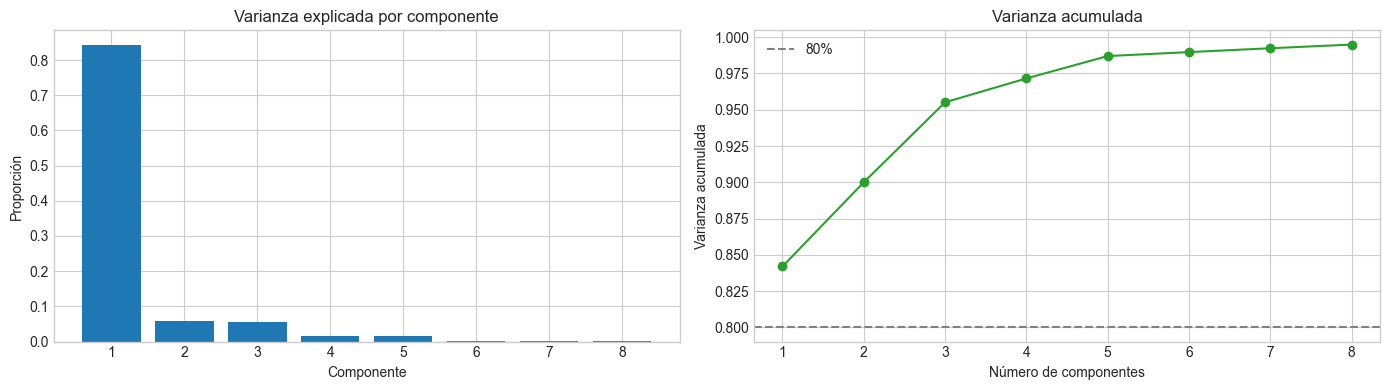

,lag_12,lag_11,lag_10,lag_9,lag_8,lag_7,lag_6,lag_5,lag_4,lag_3,lag_2,lag_1
PC1,0.289,0.289,0.289,0.290,0.290,0.290,0.290,0.289,0.288,0.288,0.287,0.285
PC2,-0.137,-0.302,-0.392,-0.377,-0.272,-0.103,0.098,0.278,0.390,0.403,0.306,0.117
PC3,0.391,0.269,0.090,-0.115,-0.278,-0.372,-0.380,-0.294,-0.129,0.095,0.302,0.435
PC4,0.007,-0.335,-0.353,-0.040,0.332,0.403,0.080,-0.310,-0.386,-0.072,0.303,0.374
PC5,0.388,0.233,-0.180,-0.408,-0.254,0.151,0.417,0.264,-0.133,-0.400,-0.245,0.165
PC6,-0.430,-0.250,0.389,0.188,-0.272,-0.166,0.169,0.246,-0.103,-0.380,0.181,0.433
PC7,-0.230,0.116,0.435,-0.344,-0.375,0.493,0.137,-0.385,-0.039,0.237,0.068,-0.114
PC8,0.224,-0.162,-0.096,0.423,-0.332,-0.235,0.538,-0.162,-0.333,0.304,0.046,-0.218


Varianza explicada acumulada del modelo elegido: 0.9949261675917331


In [8]:
X_tv, y_tv = make_supervised(train_valid.values, int(best_cfg['window']))
final_pipe = build_pipeline(best_cfg)
final_pipe.fit(X_tv, y_tv)

pca_obj = final_pipe.named_steps['pca']
exp_var = pca_obj.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(1, len(exp_var) + 1), exp_var, color='tab:blue')
axes[0].set_title('Varianza explicada por componente')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Proporción')

axes[1].plot(range(1, len(exp_var) + 1), np.cumsum(exp_var), marker='o', color='tab:green')
axes[1].axhline(0.8, color='gray', linestyle='--', label='80%')
axes[1].set_title('Varianza acumulada')
axes[1].set_xlabel('Número de componentes')
axes[1].set_ylabel('Varianza acumulada')
axes[1].legend()
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(
    pca_obj.components_,
    index=[f'PC{i+1}' for i in range(pca_obj.n_components_)],
    columns=[f'lag_{k}' for k in range(int(best_cfg['window']), 0, -1)],
)

display(loadings.round(3))
print('Varianza explicada acumulada del modelo elegido:', np.cumsum(exp_var)[-1])

## 8) Diagnóstico de residuos del modelo final

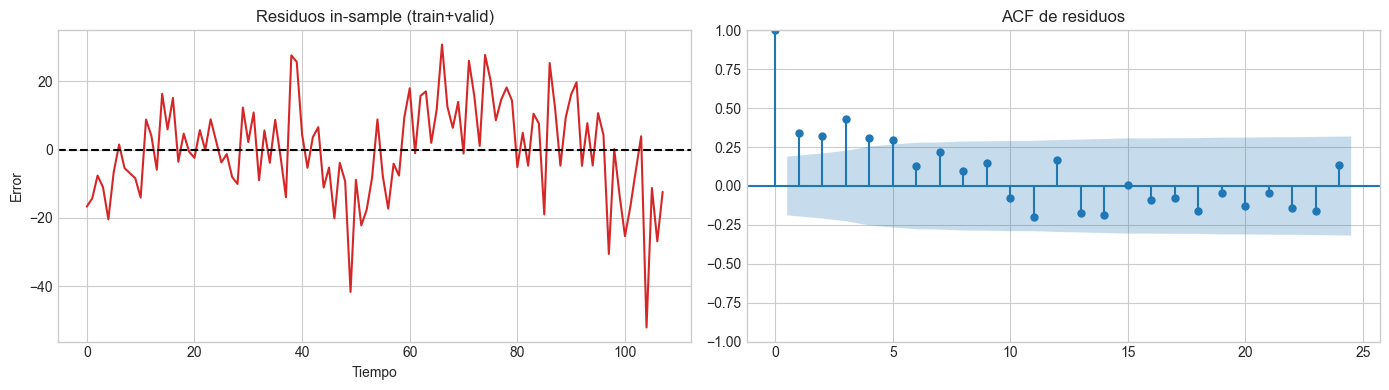

,lb_stat,lb_pvalue
12,86.455708,2.387807e-13


Hay evidencia de autocorrelación residual (p <= 0.05).


In [9]:
fitted_tv = final_pipe.predict(X_tv)
residuos_tv = y_tv - fitted_tv

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(residuos_tv, color='tab:red')
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title('Residuos in-sample (train+valid)')
axes[0].set_xlabel('Tiempo')
axes[0].set_ylabel('Error')

plot_acf(pd.Series(residuos_tv), lags=24, ax=axes[1])
axes[1].set_title('ACF de residuos')
plt.tight_layout()
plt.show()

lb = acorr_ljungbox(pd.Series(residuos_tv), lags=[12], return_df=True)
display(lb)

if lb['lb_pvalue'].iloc[0] > 0.05:
    print('No hay evidencia fuerte de autocorrelación residual (p > 0.05).')
else:
    print('Hay evidencia de autocorrelación residual (p <= 0.05).')

## 9) Actividades para estudiantes

1. Repite la selección con otra grilla (más fina) de `window` y `n_components`.
2. Cambia el criterio de selección a MAPE y compara el modelo ganador.
3. Implementa validación rolling-origin con 3 folds y horizonte 12.
4. Intenta un modelo sin PCA (Ridge directo con lags) y compara contra PCA.
5. Escribe una conclusión: ¿cuánto ayudó PCA en desempeño e interpretabilidad?

## 10) Cierre

Este pipeline sigue el esquema teórico de clase:

Reducir (PCA) -> Modelar (Linear/Ridge) -> Validar (walk-forward) -> Interpretar (loadings) -> Diagnosticar (residuos).

### Nota de teoría (SSA)

En línea con las slides, este enfoque de lag-embedding conecta con la intuición de SSA: representar la dinámica temporal en un espacio de mayor dimensión y extraer sus modos principales mediante descomposición lineal.

## 11) Extensión: PCA con panel multiserie S&P 500 (2024-2025)

Ahora aplicamos la misma lógica al archivo `sp500_tickers_2024_2025.csv`:

- Cada fecha contiene retornos de múltiples tickers.
- Usamos PCA para extraer factores latentes del panel cross-sectional.
- Pronosticamos el **retorno del siguiente día** para un ticker objetivo.
- Seleccionamos técnica y parámetros con validación temporal walk-forward.

In [10]:
sp = pd.read_csv('sp500_tickers_2024_2025.csv', parse_dates=['Date'])
sp = sp.sort_values(['Date', 'Ticker']).reset_index(drop=True)

# Construimos un panel: filas=fecha, columnas=ticker, valores=retorno diario.
ret_panel = sp.pivot(index='Date', columns='Ticker', values='Daily_Return')
ret_panel = ret_panel.sort_index()

# VIX (una observación por fecha, compartida por tickers).
vix_series = sp.groupby('Date')['Volatility_Index'].mean().sort_index()

panel = ret_panel.join(vix_series.rename('VIX'), how='inner')
panel = panel.dropna()

print(f'Fechas disponibles: {panel.index.min().date()} -> {panel.index.max().date()}')
print(f'Dimensión panel limpio: {panel.shape[0]} fechas x {panel.shape[1]} variables')
print(f'Tickers usados: {ret_panel.columns.nunique()}')
display(panel.head())

Fechas disponibles: 2024-01-03 -> 2025-12-30
Dimensión panel limpio: 500 fechas x 21 variables
Tickers usados: 20


,AAPL,AMZN,AVGO,BRK-B,COST,GOOGL,HD,JNJ,JPM,LLY,MA,META,MSFT,NVDA,PG,TSLA,UNH,V,WMT,XOM,VIX
Date,,,,,,,,,,,,,,,,,,,,,
2024-01-03,-0.007488,-0.009738,-0.024692,0.011836,-0.009160,0.005428,-0.019764,0.006251,-0.004359,0.043060,-0.007395,-0.005256,-0.000728,-0.012436,-0.006051,-0.040134,0.004988,-0.003438,0.000063,0.008402,14.04
2024-01-04,-0.012700,-0.026268,-0.009040,-0.008371,0.005677,-0.018212,0.000976,-0.002112,0.006636,-0.005181,0.002388,0.007693,-0.007178,0.009018,0.005479,-0.002181,0.006254,0.006318,-0.009667,-0.008719,14.13
2024-01-05,-0.004013,0.004634,0.000257,0.005252,0.011815,-0.004839,0.012847,0.003113,0.005017,0.006591,-0.000834,0.013915,-0.000516,0.022897,-0.008274,-0.001849,-0.014741,0.000308,-0.006656,0.003030,13.35
2024-01-08,0.024175,0.026577,0.024369,0.007084,0.008658,0.022913,0.014551,0.002482,-0.001451,0.012093,0.007689,0.019065,0.018871,0.064281,0.008615,0.012464,-0.001600,0.010975,0.009827,-0.016662,13.08
2024-01-09,-0.002263,0.015225,0.007108,-0.003477,0.008297,0.015197,-0.005001,0.000619,-0.007906,-0.000879,0.001469,-0.003429,0.002936,0.016975,0.004103,-0.022832,0.003448,0.003009,0.006698,-0.012386,12.76


Train: 2024-01-03 -> 2025-07-10 | n=380
Valid: 2025-07-11 -> 2025-10-03 | n=60
Test : 2025-10-06 -> 2025-12-30 | n=60


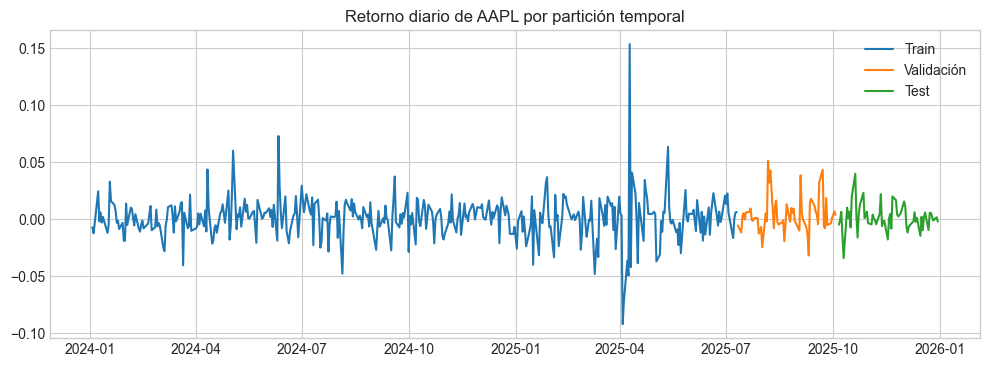

In [11]:
target_ticker = 'AAPL'
ticker_cols = sorted([c for c in panel.columns if c != 'VIX'])

if target_ticker not in ticker_cols:
    raise ValueError(f'Ticker objetivo {target_ticker} no está en el panel.')

# Split temporal por fechas.
n_total_panel = len(panel)
n_test_panel = 60
n_valid_panel = 60

train_panel = panel.iloc[: n_total_panel - n_valid_panel - n_test_panel].copy()
valid_panel = panel.iloc[n_total_panel - n_valid_panel - n_test_panel : n_total_panel - n_test_panel].copy()
test_panel = panel.iloc[n_total_panel - n_test_panel :].copy()

print(f'Train: {train_panel.index.min().date()} -> {train_panel.index.max().date()} | n={len(train_panel)}')
print(f'Valid: {valid_panel.index.min().date()} -> {valid_panel.index.max().date()} | n={len(valid_panel)}')
print(f'Test : {test_panel.index.min().date()} -> {test_panel.index.max().date()} | n={len(test_panel)}')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train_panel.index, train_panel[target_ticker], label='Train')
ax.plot(valid_panel.index, valid_panel[target_ticker], label='Validación')
ax.plot(test_panel.index, test_panel[target_ticker], label='Test')
ax.set_title(f'Retorno diario de {target_ticker} por partición temporal')
ax.legend()
plt.show()

In [12]:
def fit_panel_model_and_predict_next(history_df, cfg, target, tickers):
    X_panel = history_df[tickers].iloc[:-1].values
    y_next = history_df[target].shift(-1).dropna().values

    if cfg['scale']:
        scaler = StandardScaler()
        X_proc = scaler.fit_transform(X_panel)
    else:
        scaler = None
        X_proc = X_panel

    pca = PCA(n_components=int(cfg['n_components']))
    Z = pca.fit_transform(X_proc)

    if cfg['use_vix']:
        vix_train = history_df['VIX'].iloc[:-1].values.reshape(-1, 1)
        X_train = np.hstack([Z, vix_train])
    else:
        X_train = Z

    if cfg['technique'] == 'PCA+Linear':
        model = LinearRegression()
    else:
        model = Ridge(alpha=float(cfg['alpha']))

    model.fit(X_train, y_next)

    x_last = history_df[tickers].iloc[[-1]].values
    if scaler is not None:
        x_last = scaler.transform(x_last)

    z_last = pca.transform(x_last)

    if cfg['use_vix']:
        vix_last = np.array([[history_df['VIX'].iloc[-1]]])
        x_pred = np.hstack([z_last, vix_last])
    else:
        x_pred = z_last

    y_pred_next = float(model.predict(x_pred)[0])
    return y_pred_next


def walk_forward_panel(initial_df, eval_df, cfg, target, tickers):
    history = initial_df.copy()
    preds = []

    for dt in eval_df.index:
        pred = fit_panel_model_and_predict_next(history, cfg, target, tickers)
        preds.append(pred)

        # Se agrega la observación real del día actual para el siguiente paso.
        history = pd.concat([history, eval_df.loc[[dt]]], axis=0)

    return np.array(preds)

In [13]:
panel_techniques = ['PCA+Linear', 'PCA+Ridge']
panel_scales = [False, True]
panel_use_vix = [False, True]
panel_n_components = [2, 3, 5, 8, 12]
panel_alphas = [0.1, 1.0, 10.0]

panel_configs = []
for tech, scale, use_vix, n_comp in product(panel_techniques, panel_scales, panel_use_vix, panel_n_components):
    if n_comp >= len(ticker_cols):
        continue

    if tech == 'PCA+Linear':
        panel_configs.append({
            'technique': tech,
            'scale': scale,
            'use_vix': use_vix,
            'n_components': n_comp,
            'alpha': np.nan,
        })
    else:
        for a in panel_alphas:
            panel_configs.append({
                'technique': tech,
                'scale': scale,
                'use_vix': use_vix,
                'n_components': n_comp,
                'alpha': a,
            })

panel_results = []
for cfg in panel_configs:
    try:
        pred_valid_panel = walk_forward_panel(train_panel, valid_panel, cfg, target_ticker, ticker_cols)
        m = eval_metrics(valid_panel[target_ticker].values, pred_valid_panel)
        panel_results.append({**cfg, **m})
    except Exception:
        continue

panel_results_df = pd.DataFrame(panel_results).sort_values('RMSE').reset_index(drop=True)
print(f'Configuraciones panel evaluadas: {len(panel_results_df)}')
display(panel_results_df.head(12))

Configuraciones panel evaluadas: 80


,technique,scale,use_vix,n_components,alpha,MAE,RMSE,MAPE_%
0,PCA+Ridge,True,False,3,10.0,0.011027,0.015719,114.484582
1,PCA+Ridge,True,False,3,1.0,0.011030,0.015719,114.640274
2,PCA+Ridge,True,False,3,0.1,0.011030,0.015719,114.656082
3,PCA+Linear,True,False,3,NaN,0.011030,0.015719,114.657841
4,PCA+Ridge,False,False,2,10.0,0.010812,0.015725,104.034876
5,PCA+Ridge,True,True,3,10.0,0.011008,0.015726,114.101446
6,PCA+Ridge,True,True,3,1.0,0.011011,0.015727,114.261642
7,PCA+Ridge,True,True,3,0.1,0.011012,0.015727,114.277903
8,PCA+Linear,True,True,3,NaN,0.011012,0.015727,114.279713
9,PCA+Ridge,False,True,2,10.0,0.010774,0.015727,101.649698


Mejor configuración panel (validación):
{'technique': 'PCA+Ridge', 'scale': True, 'use_vix': False, 'n_components': 3, 'alpha': 10.0, 'MAE': 0.011027224153306573, 'RMSE': 0.01571906794201673, 'MAPE_%': 114.48458162465849}


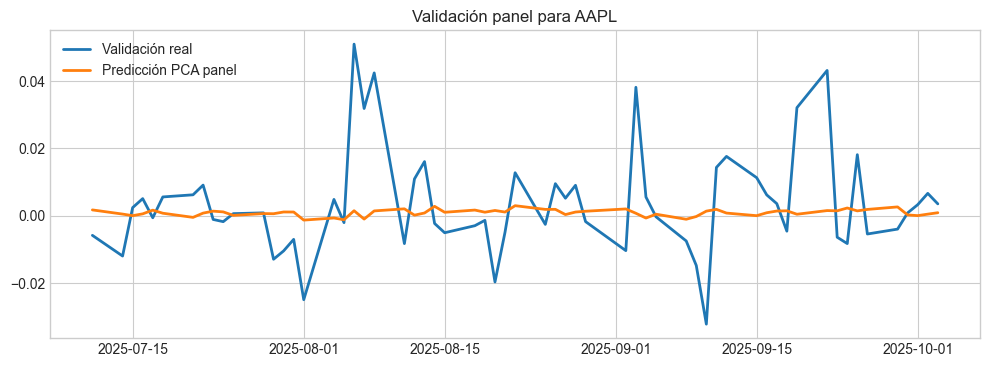

Métricas validación panel:
{'MAE': np.float64(0.011027224153306573), 'RMSE': np.float64(0.01571906794201673), 'MAPE_%': np.float64(114.48458162465849)}


In [14]:
best_panel_cfg = panel_results_df.iloc[0].to_dict()
print('Mejor configuración panel (validación):')
print(best_panel_cfg)

pred_valid_panel_best = walk_forward_panel(train_panel, valid_panel, best_panel_cfg, target_ticker, ticker_cols)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(valid_panel.index, valid_panel[target_ticker], label='Validación real', lw=2)
ax.plot(valid_panel.index, pred_valid_panel_best, label='Predicción PCA panel', lw=2)
ax.set_title(f'Validación panel para {target_ticker}')
ax.legend()
plt.show()

print('Métricas validación panel:')
print(eval_metrics(valid_panel[target_ticker].values, pred_valid_panel_best))

,modelo,MAE,RMSE,MAPE_%
0,PCA panel (mejor),0.007976,0.011199,133.166325
1,Naive retorno,0.011049,0.014374,707.595077


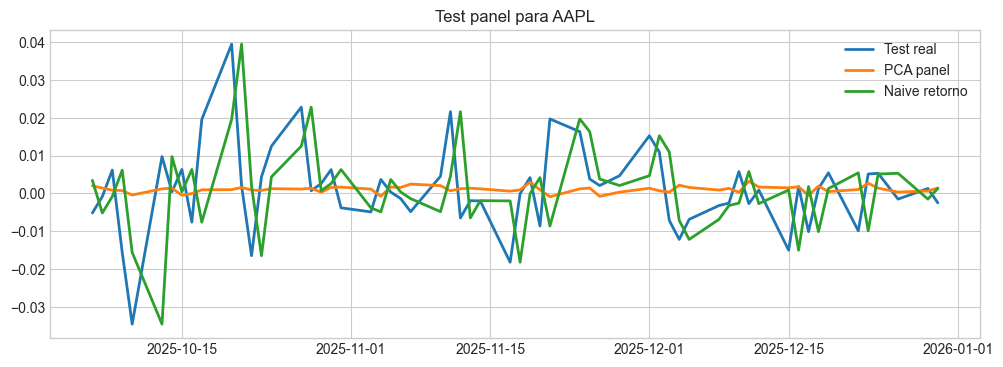

In [15]:
panel_train_valid = pd.concat([train_panel, valid_panel], axis=0)

pred_test_panel_best = walk_forward_panel(panel_train_valid, test_panel, best_panel_cfg, target_ticker, ticker_cols)

# Baseline: retorno de manana igual al retorno de hoy (naive random-walk en retornos).
def naive_return_walk_forward(initial_df, eval_df, target):
    history = initial_df.copy()
    preds = []
    for dt in eval_df.index:
        preds.append(float(history[target].iloc[-1]))
        history = pd.concat([history, eval_df.loc[[dt]]], axis=0)
    return np.array(preds)

pred_test_panel_naive = naive_return_walk_forward(panel_train_valid, test_panel, target_ticker)

panel_test_comparison = pd.DataFrame([
    {'modelo': 'PCA panel (mejor)', **eval_metrics(test_panel[target_ticker].values, pred_test_panel_best)},
    {'modelo': 'Naive retorno', **eval_metrics(test_panel[target_ticker].values, pred_test_panel_naive)},
]).sort_values('RMSE')

display(panel_test_comparison)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test_panel.index, test_panel[target_ticker], label='Test real', lw=2)
ax.plot(test_panel.index, pred_test_panel_best, label='PCA panel', lw=2)
ax.plot(test_panel.index, pred_test_panel_naive, label='Naive retorno', lw=2)
ax.set_title(f'Test panel para {target_ticker}')
ax.legend()
plt.show()

## 12) Actividad extra sugerida (panel)

1. Cambia `target_ticker` por otro activo (por ejemplo `MSFT`, `NVDA`, `JPM`).
2. Repite la selección y compara si el número óptimo de componentes cambia.
3. Evalúa si incluir `VIX` mejora consistentemente el RMSE.
4. Extiende el pipeline para predecir horizonte de 5 días acumulando pronósticos one-step.

### Métricas recomendadas para retornos

Como los retornos suelen estar cerca de cero, MAPE puede inflarse y volverse poco estable.
Por eso, para esta sección panel conviene complementar con:

- MAE / RMSE
- Accuracy direccional (acierto de signo)
- Correlación entre retorno real y predicho

In [16]:
def directional_accuracy(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(np.sign(y_true) == np.sign(y_pred))


def safe_corr(y_true, y_pred):
    if np.std(y_true) < 1e-12 or np.std(y_pred) < 1e-12:
        return np.nan
    return np.corrcoef(y_true, y_pred)[0, 1]

panel_extra_metrics = pd.DataFrame([
    {
        'modelo': 'PCA panel (mejor)',
        'Directional_Acc': directional_accuracy(test_panel[target_ticker].values, pred_test_panel_best),
        'Corr': safe_corr(test_panel[target_ticker].values, pred_test_panel_best),
    },
    {
        'modelo': 'Naive retorno',
        'Directional_Acc': directional_accuracy(test_panel[target_ticker].values, pred_test_panel_naive),
        'Corr': safe_corr(test_panel[target_ticker].values, pred_test_panel_naive),
    },
])

display(panel_extra_metrics)

,modelo,Directional_Acc,Corr
0,PCA panel (mejor),0.533333,0.007447
1,Naive retorno,0.516667,0.172160
